# Exploring a synthetic hidradenitis suppurativa (HS) clinical record
**Goal:** describe the cohort, look for sub-populations, unusual features, trends — and separate *real clinical signal* from *recording artefacts*.

**What is in this notebook** (read top to bottom; every code cell is preceded by *why* we run it and followed by *what we saw*):

| # | Section | Statistical idea you can learn from it |
|---|---|---|
| 1-2 | Load, join, patient table, cohort-assembly artefacts | join integrity, redundant columns, left-truncation |
| 3 | Missingness | MCAR vs informative missingness |
| 4 | Cohort "Table 1" | stratified descriptives, confounding by indication |
| 5 | Antibiotics & biologic lines | Kaplan-Meier, censoring, hazards |
| 6 | Surgeries, antibiotic-surgery coupling | permutation null, event coupling |
| 7 | Trends, event-time plot, super-responder proxy | person-time denominators, zero-inflation |
| 8 | Practitioners | overdispersion, permutation test |
| 9 | Sub-populations | clustering, silhouette, rule-based segments |
| 10 | With the target: baselines, drivers, super-responders | MAE ladder, mixtures, AUC |
| 11 | Take-aways | |

**Scope.** Inputs: `demographics`, `patient_assignment`, `surgeries`, `treatments` and `targets` (all 21,000 *train* patients). `visits.csv` (the IHS4 scores) was too large to share, so sections 1-9 describe the record with antibiotics/surgeries as activity proxies; section 10 brings in the target. Visit-level analysis lives in the separate template notebook.

**The cut-off rule.** Everything is computed "as of" 31-Dec-2025 (`END`), the same limit the challenge sets, so no feature here could leak the future.

# 00 - Setup

In [1]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# 01 - Load and checking

In [2]:
# Load data
BASE = "https://raw.githubusercontent.com/FairzanIsLearning/Chemometric-learn/main/Mixed/HS_Model/Raw_data/"

demo = pd.read_csv(BASE + "demographics.csv",      parse_dates=["symptom_onset_date", "diagnosis_date"])
prac = pd.read_csv(BASE + "patient_assignment.csv")
surg = pd.read_csv(BASE + "surgeries.csv",         parse_dates=["procedure_date"])
trt  = pd.read_csv(BASE + "treatments.csv",        parse_dates=["start_date", "end_date"])

summary = pd.DataFrame({
    "rows":     [len(demo), len(prac), len(surg), len(trt)],
    "patients": [demo.patient_id.nunique(), prac.patient_id.nunique(),
                 surg.patient_id.nunique(), trt.patient_id.nunique()],
}, index=["demographics", "patient_assignment", "surgeries", "treatments"])
summary["share_of_cohort"] = summary.patients / demo.patient_id.nunique()

# Join integrity: every id in the child tables must exist in demographics
orphans = {n: len(set(t.patient_id) - set(demo.patient_id)) for n, t in
           [("assignment", prac), ("surgeries", surg), ("treatments", trt)]}
print("Orphan patient ids per table:", orphans)
print("Duplicate surgery ids:", surg.surgery_id.duplicated().sum(),
      "| duplicate treatment ids:", trt.treatment_id.duplicated().sum())
summary

Orphan patient ids per table: {'assignment': 0, 'surgeries': 0, 'treatments': 0}
Duplicate surgery ids: 0 | duplicate treatment ids: 0


,rows,patients,share_of_cohort
demographics,21000,21000,1.000
patient_assignment,21000,21000,1.000
surgeries,60036,12326,0.587
treatments,203812,20294,0.966


In [3]:
# 1) Are some columns just re-computations of others?
dx_year = demo.diagnosis_date.dt.year
print("age_at_diagnosis == diagnosis_year - birth_year for", ((dx_year - demo.birth_year) == demo.age_at_diagnosis).mean().__round__(4) * 100, "% of patients")

delay_calc = ((demo.diagnosis_date - demo.symptom_onset_date).dt.days / 365.25).round(1)
both = demo.diagnostic_delay_years.notna() & demo.symptom_onset_date.notna()
print("diagnostic_delay_years matches (diagnosis - onset)/365.25 in", ((delay_calc[both] - demo.diagnostic_delay_years[both]).abs() < 0.11).mean().__round__(4) * 100, "% of rows where both exist")

# 2) The two columns are masked INDEPENDENTLY -> one can often rebuild the other
onset_missing = demo.symptom_onset_date.isna(); delay_missing = demo.diagnostic_delay_years.isna()
print(pd.crosstab(onset_missing.rename("onset_missing"), delay_missing.rename("delay_missing"), margins=True))
rec = delay_missing & ~onset_missing        # delay can be recomputed from dates
rec2 = onset_missing & ~delay_missing       # onset can be recomputed from delay
print(f"Recoverable delay: {rec.sum()} | recoverable onset: {rec2.sum()} | truly unknown both: {(onset_missing & delay_missing).sum()}")

age_at_diagnosis == diagnosis_year - birth_year for 100.0 % of patients
diagnostic_delay_years matches (diagnosis - onset)/365.25 in 100.0 % of rows where both exist
delay_missing  False  True    All
onset_missing                    
False          12225  3526  15751
True            3460  1789   5249
All            15685  5315  21000
Recoverable delay: 3526 | recoverable onset: 3460 | truly unknown both: 1789


# 02 - Data fusion
every later analysis needs patient-level summaries. Key design choices: (1) **exposure** = years from diagnosis to `END`; (2) rates use exposure limited to 3 months; (3) everything uses dates ≤ `END`.

In [4]:
# function helper -- general

def count_by_patient(df, name, mask=None):
    d = df if mask is None else df[mask]
    return d.groupby("patient_id").size().rename(name)

In [6]:
# Build one row per patient, using only information available on END 
END = pd.Timestamp("2025-12-31")
pt = demo.merge(prac, on="patient_id")
pt["dx_year"] = pt.diagnosis_date.dt.year
pt["obs_years"] = (END - pt.diagnosis_date).dt.days / 365.25  # follow-up time since diagnosis

# treatment type
abx = trt[trt.treatment_class == "Antibiotic"]
bio = trt[trt.treatment_class == "Biologic"].sort_values(["patient_id", "start_date"])

pt = pt.set_index("patient_id")
pt["n_abx"]       = count_by_patient(abx, "n_abx")
pt["n_abx_12m"]   = count_by_patient(abx, "x", abx.start_date > END - pd.Timedelta(days=365))
pt["n_surg"]      = count_by_patient(surg, "n_surg")
pt["n_surg_12m"]  = count_by_patient(surg, "x", surg.procedure_date > END - pd.Timedelta(days=365))
pt["n_bio_lines"] = count_by_patient(bio, "n_bio_lines")
for c in ["n_abx", "n_abx_12m", "n_surg", "n_surg_12m", "n_bio_lines"]:
    pt[c] = pt[c].fillna(0).astype(int)

open_line = bio[bio.end_date.isna()].set_index("patient_id")
pt["on_bio"]       = pt.index.isin(open_line.index)   # open biologic line at END
pt["ever_bio"]     = pt.n_bio_lines > 0
pt["cur_drug"]     = open_line.drug_name
pt["cur_line_no"]  = open_line.treatment_line
pt["days_on_cur"]  = (END - open_line.start_date).dt.days
pt["first_bio_start"] = bio.groupby("patient_id").start_date.min()
pt["bio_status"]   = np.select([pt.on_bio, pt.ever_bio], ["on biologic", "stopped biologic"], "never biologic")

# Rates need a sensible denominator: clip very short follow-up so new patients don't explode
pt["exposure"]  = pt.obs_years.clip(lower=0.25)
pt["abx_rate"]  = pt.n_abx / pt.exposure
pt["surg_rate"] = pt.n_surg / pt.exposure
pt = pt.reset_index()
pt[["patient_id","hurley_stage_baseline","obs_years","n_abx","n_surg","n_bio_lines","bio_status","cur_drug","days_on_cur"]].head()

,patient_id,hurley_stage_baseline,obs_years,n_abx,n_surg,n_bio_lines,bio_status,cur_drug,days_on_cur
0,HS000001,2,3.296,9,4,1,stopped biologic,NaN,NaN
1,HS000003,2,8.843,24,6,2,stopped biologic,NaN,NaN
2,HS000004,3,2.021,5,2,2,stopped biologic,NaN,NaN
3,HS000008,1,8.496,9,1,0,never biologic,NaN,NaN
4,HS000009,3,3.743,8,3,1,stopped biologic,NaN,NaN


# 03 - Data missing

Missing rate per field:
 ethnicity                0.076
bmi_at_baseline          0.101
smoking_status           0.119
symptom_onset_date       0.250
diagnostic_delay_years   0.253
family_history_hs        0.171


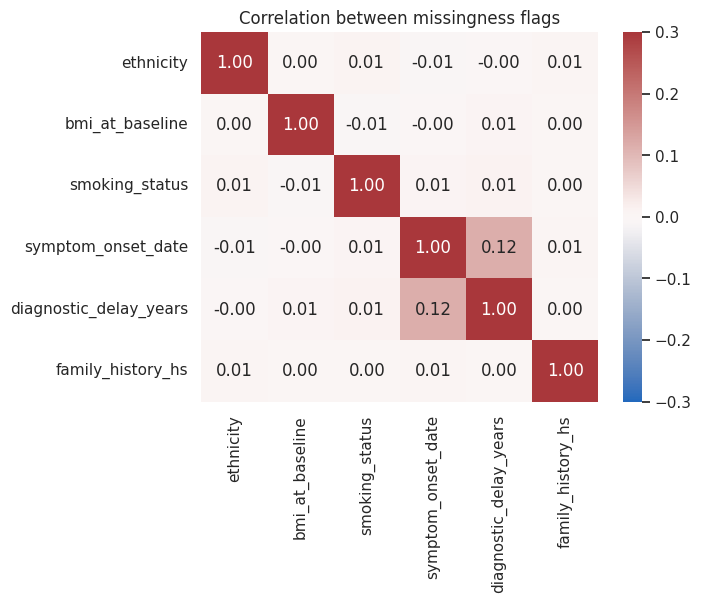

,field,outcome,mean_if_missing,mean_if_present,p,p_bonferroni
21,family_history_hs,abx_rate,1.904,1.834,0.001,0.026
14,symptom_onset_date,surg_rate,0.596,0.582,0.026,0.622
9,smoking_status,abx_rate,1.820,1.849,0.031,0.739
5,bmi_at_baseline,abx_rate,1.896,1.840,0.031,0.753
17,diagnostic_delay_years,abx_rate,1.816,1.856,0.038,0.910
20,family_history_hs,hurley_stage_baseline,1.966,1.942,0.078,1.000
18,diagnostic_delay_years,surg_rate,0.602,0.580,0.101,1.000
13,symptom_onset_date,abx_rate,1.826,1.853,0.136,1.000


In [7]:
# Missingness: how much, and is it related to anything we can see?
fields = ["ethnicity", "bmi_at_baseline", "smoking_status", "symptom_onset_date", "diagnostic_delay_years", "family_history_hs"]
miss = pt[fields].isna()
print("Missing rate per field:\n", miss.mean().round(3).to_string())

# a) Are the missingness flags correlated with each other? (phi coefficient = Pearson on 0/1)
sns.heatmap(miss.astype(int).corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-.3, vmax=.3)
plt.title("Correlation between missingness flags"); plt.show()

# b) Is missingness related to clinical content? Mann-Whitney / chi-square, one test per field x outcome
rows = []
for f in fields:
    flag = miss[f]
    for outcome in ["hurley_stage_baseline", "abx_rate", "surg_rate", "on_bio"]:
        a, b = pt.loc[flag, outcome].astype(float), pt.loc[~flag, outcome].astype(float)
        p = stats.mannwhitneyu(a, b).pvalue
        rows.append((f, outcome, a.mean(), b.mean(), p))
mt = pd.DataFrame(rows, columns=["field", "outcome", "mean_if_missing", "mean_if_present", "p"])
mt["p_bonferroni"] = (mt.p * len(mt)).clip(upper=1)
mt.sort_values("p").head(8)

# 04 - hurley stage classification
the cohort's main severity label.

In [8]:
# "Table 1": the cohort at a glance, split by baseline Hurley stage (the main severity label)
t1 = pt.groupby("hurley_stage_baseline").agg(
    patients=("patient_id", "size"),
    age_at_dx=("age_at_diagnosis", "mean"),
    female=("sex", lambda x: (x == "Female").mean()),
    bmi=("bmi_at_baseline", "mean"),
    current_smoker=("smoking_status", lambda x: (x == "Current").sum() / x.notna().sum()),
    family_hx_yes=("family_history_hs", lambda x: (x == "Yes").sum() / x.isin(["Yes", "No"]).sum()),
    delay_years=("diagnostic_delay_years", "mean"),
    on_biologic=("on_bio", "mean"),
    ever_biologic=("ever_bio", "mean"),
    abx_per_year=("abx_rate", "mean"),
    surgeries_per_year=("surg_rate", "mean"),
    no_surgery=("n_surg", lambda x: (x == 0).mean()),
    untreated=("n_abx", lambda x: ((x == 0)).mean()),
)
t1.T

hurley_stage_baseline,1,2,3
patients,"6,280.000","9,565.000","5,155.000"
age_at_dx,28.636,28.746,28.627
female,0.721,0.718,0.722
bmi,31.655,31.690,31.880
current_smoker,0.385,0.387,0.388
family_hx_yes,0.370,0.369,0.367
delay_years,4.216,4.295,4.117
on_biologic,0.000,0.586,0.571
ever_biologic,0.000,0.890,0.890
abx_per_year,1.287,2.025,2.195


In [9]:
# Does anything other than Hurley stage predict who gets a biologic?  (confounding-by-indication check)
elig = pt[pt.hurley_stage_baseline >= 2].copy()
print("Biologic use by Hurley:", pt.groupby("hurley_stage_baseline")[["on_bio","ever_bio"]].mean().round(3).to_dict("index"))

rows = []
for c in ["sex", "ethnicity", "smoking_status", "family_history_hs"]:
    ct = pd.crosstab(elig[c].fillna("missing"), elig.on_bio)
    rows.append((c, stats.chi2_contingency(ct)[1]))
for c in ["age_at_diagnosis", "bmi_at_baseline", "diagnostic_delay_years", "obs_years"]:
    d = elig[[c, "on_bio"]].dropna()
    rows.append((c, stats.mannwhitneyu(d[d.on_bio][c], d[~d.on_bio][c]).pvalue))
pd.DataFrame(rows, columns=["variable", "p_vs_on_biologic"]).set_index("variable")

Biologic use by Hurley: {1: {'on_bio': 0.0, 'ever_bio': 0.0}, 2: {'on_bio': 0.586, 'ever_bio': 0.89}, 3: {'on_bio': 0.571, 'ever_bio': 0.89}}


,p_vs_on_biologic
variable,
sex,0.861
ethnicity,0.450
smoking_status,0.364
family_history_hs,0.437
age_at_diagnosis,0.975
bmi_at_baseline,0.607
diagnostic_delay_years,0.173
obs_years,0.000


# 05 - treatment details

In [10]:
# function helper -- analysis

# Kaplan-Meier "survival on drug" for line 1 (hand-written so you can see what it does)
def km(duration, event):
    d = pd.DataFrame({"t": duration, "e": event}).sort_values("t")
    at_risk, s, T, S = len(d), 1.0, [0], [1.0]
    for t, g in d.groupby("t"):
        deaths = g.e.sum()
        if deaths: s *= 1 - deaths / at_risk
        T.append(t); S.append(s); at_risk -= len(g)
    return np.array(T), np.array(S)

In [11]:
# Antibiotic courses: what do they look like?
print("Course length in days (all antibiotic classes):", (abx.end_date - abx.start_date).dt.days.value_counts().to_dict())
mix = abx.merge(pt[["patient_id", "hurley_stage_baseline", "bio_status"]], on="patient_id")

print("\nShare of each antibiotic by Hurley stage")
print(pd.crosstab(mix.hurley_stage_baseline, mix.drug_name, normalize="index").round(3))

print("\nShare of each antibiotic by current biologic status")
print(pd.crosstab(mix.bio_status, mix.drug_name, normalize="index").round(3))

Course length in days (all antibiotic classes): {14: 185945, 13: 130, 10: 120, 8: 111, 5: 106, 7: 105, 12: 102, 9: 101, 2: 100, 1: 98, 3: 95, 6: 91, 4: 88, 11: 88, 0: 85}

Share of each antibiotic by Hurley stage
drug_name              Clindamycin + Rifampicin  Clindamycin topical  Tetracyclines (oral)
hurley_stage_baseline                                                                     
1                                         0.198                0.600                 0.202
2                                         0.200                0.599                 0.201
3                                         0.201                0.600                 0.199

Share of each antibiotic by current biologic status
drug_name         Clindamycin + Rifampicin  Clindamycin topical  Tetracyclines (oral)
bio_status                                                                           
never biologic                       0.199                0.599                 0.202
on biologic          

treatment_line column agrees with order of start dates: 1.0

First-line drug: {'Adalimumab': 0.999, 'Bimekizumab': 0.0005, 'Secukinumab': 0.0005}

Most common biologic pathways:
drug_name
Adalimumab                                10365
Adalimumab > Bimekizumab                   1063
Adalimumab > Secukinumab                   1039
Adalimumab > Bimekizumab > Secukinumab      332
Adalimumab > Secukinumab > Bimekizumab      288
Bimekizumab                                   6

Closed lines: 7899; followed by another line: 42.4%
Gap (days) before next line: {'count': 3347.0, 'mean': 44.2, 'std': 17.6, 'min': 14.0, '25%': 29.0, '50%': 44.0, '75%': 60.0, 'max': 74.0}


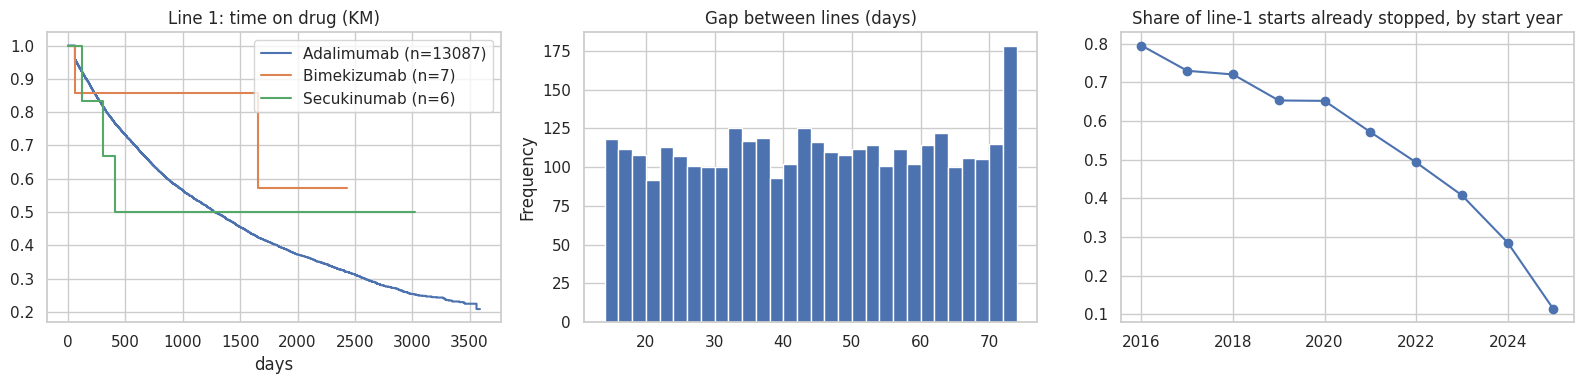

Shortest completed line (days): 60


In [12]:
# Biologic lines: sequences, switching gaps, survival on a line
b = bio.copy()
b["seq_no"] = b.groupby("patient_id").cumcount() + 1
print("treatment_line column agrees with order of start dates:", (b.seq_no == b.treatment_line).mean().round(4))

first = b[b.seq_no == 1]
print("\nFirst-line drug:", first.drug_name.value_counts(normalize=True).round(4).to_dict())

seqs = b.groupby("patient_id").drug_name.apply(" > ".join).value_counts()
print("\nMost common biologic pathways:"); print(seqs.head(6).to_string())

# Gap between the end of one line and the start of the next
b["next_start"] = b.groupby("patient_id").start_date.shift(-1)
b["gap_days"] = (b.next_start - b.end_date).dt.days
closed = b[b.end_date.notna()]
print(f"\nClosed lines: {len(closed)}; followed by another line: {closed.next_start.notna().mean():.1%}")
print("Gap (days) before next line:", closed.gap_days.describe().round(1).to_dict())

# graph
first = first.assign(dur=(first.end_date.fillna(END) - first.start_date).dt.days, stopped=first.end_date.notna())
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for drug, g in first.groupby("drug_name"):
    T, S = km(g.dur, g.stopped); ax[0].step(T, S, where="post", label=f"{drug} (n={len(g)})")
ax[0].set_title("Line 1: time on drug (KM)"); ax[0].set_xlabel("days"); ax[0].legend()
closed.gap_days.dropna().plot.hist(bins=30, ax=ax[1]); ax[1].set_title("Gap between lines (days)")
first.assign(y=first.start_date.dt.year).groupby("y").stopped.mean().plot(ax=ax[2], marker="o")
ax[2].set_title("Share of line-1 starts already stopped, by start year"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

print("Shortest completed line (days):", closed.assign(d=(closed.end_date-closed.start_date).dt.days).d.min())

Hurley 2: median time to first biologic = 0.82 years; started by 1y/2y/5y = 59% / 84% / 93%
Hurley 3: median time to first biologic = 0.79 years; started by 1y/2y/5y = 60% / 84% / 93%


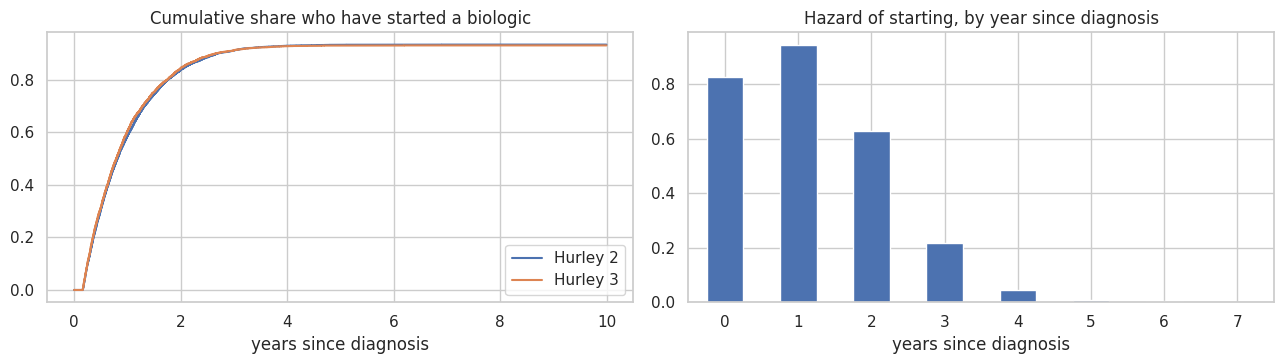

Shortest time from diagnosis to biologic start (days): 60


In [13]:
# Time from diagnosis to FIRST biologic (Hurley 2-3 only), with censoring at END (Kaplan-Meier)
H2 = pt[pt.hurley_stage_baseline >= 2].copy()
H2["t"] = (H2.first_bio_start.fillna(END) - H2.diagnosis_date).dt.days
H2["started"] = H2.first_bio_start.notna()

# graph
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))

# median start time timeline to start biologic based on hurley stage
for h, g in H2.groupby("hurley_stage_baseline"):
    T, S = km(g.t, g.started); ax[0].step(T / 365.25, 1 - S, where="post", label=f"Hurley {h}")
    med = T[np.argmax(S <= .5)] / 365.25
    print(f"Hurley {h}: median time to first biologic = {med:.2f} years; started by 1y/2y/5y = "
          + " / ".join(f"{1 - S[np.searchsorted(T, d * 365.25) - 1]:.0%}" for d in (1, 2, 5)))
ax[0].set_title("Cumulative share who have started a biologic"); ax[0].set_xlabel("years since diagnosis"); ax[0].legend()

# Discrete-time hazard: starts in year k / person-years still waiting in year k
haz = {}
for k in range(0, 8):
    waiting = (H2.t / 365.25 - k).clip(0, 1).sum()
    starts = (H2.started & (H2.t / 365.25 >= k) & (H2.t / 365.25 < k + 1)).sum()
    haz[k] = starts / waiting
pd.Series(haz).plot.bar(ax=ax[1], rot=0); ax[1].set_title("Hazard of starting, by year since diagnosis"); ax[1].set_xlabel("years since diagnosis")
plt.tight_layout(); plt.show()

print("Shortest time from diagnosis to biologic start (days):", H2.loc[H2.started, "t"].min())

# 06 -- surgery

In [14]:
# function helper -- general

def signed_gap(surgery_dates):
    s = surgery_dates.sort_values("procedure_date")
    m = pd.merge_asof(s, a_sorted, left_on="procedure_date", right_on="start_date", by="patient_id", direction="nearest")
    return (m.start_date - m.procedure_date).dt.days

In [15]:
# do the recorded outcomes carry any information?
s2 = surg.merge(pt[["patient_id", "hurley_stage_baseline", "practitioner_id"]], on="patient_id")
print(s2.groupby("procedure_type")[["recurrence_within_6mo", "wound_healing_weeks"]].agg(["mean", "std"]).round(3))

for col in ["procedure_type", "anesthesia", "hurley_stage_baseline"]:
    groups = [g.wound_healing_weeks.values for _, g in s2.groupby(col)]
    chi = stats.chi2_contingency(pd.crosstab(s2[col], s2.recurrence_within_6mo))[1]
    print(f"{col:24s} ANOVA p (healing weeks) = {stats.f_oneway(*groups).pvalue:.3f} | chi2 p (recurrence) = {chi:.3f}")

print("\nProcedure mix by Hurley stage:"); print(pd.crosstab(s2.hurley_stage_baseline, s2.procedure_type, normalize="index").round(3))

# Number of surgeries per patient: zero-inflated, overdispersed?
ns = pt.groupby("hurley_stage_baseline").n_surg.agg(mean="mean", var="var", zero_share=lambda x: (x == 0).mean())
ns["var/mean"] = ns["var"] / ns["mean"]
ns

                    recurrence_within_6mo       wound_healing_weeks      
                                     mean   std                mean   std
procedure_type                                                           
CO2 laser ablation                  0.350 0.477               6.494 2.879
Deroofing                           0.352 0.478               6.509 2.864
Incision & drainage                 0.351 0.477               6.487 2.874
Wide local excision                 0.348 0.476               6.495 2.862
procedure_type           ANOVA p (healing weeks) = 0.927 | chi2 p (recurrence) = 0.905
anesthesia               ANOVA p (healing weeks) = 0.875 | chi2 p (recurrence) = 0.551
hurley_stage_baseline    ANOVA p (healing weeks) = 0.126 | chi2 p (recurrence) = 0.078

Procedure mix by Hurley stage:
procedure_type         CO2 laser ablation  Deroofing  Incision & drainage  Wide local excision
hurley_stage_baseline                                                                         

,mean,var,zero_share,var/mean
hurley_stage_baseline,,,,
1,0.279,0.623,0.836,2.234
2,2.676,10.745,0.312,4.016
3,6.341,24.092,0.085,3.799


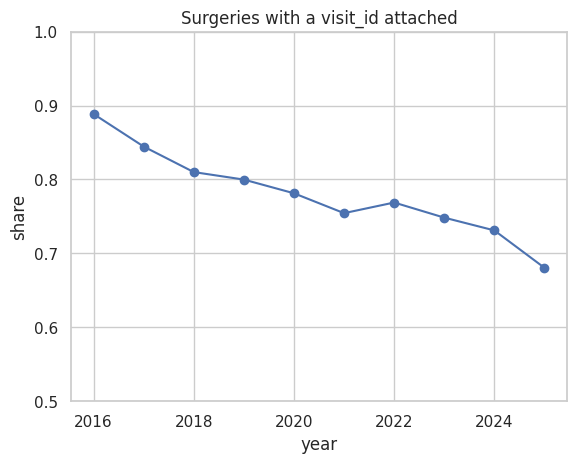

{1: 0.716, 2: 0.751, 3: 0.753}


In [16]:
# Share of surgeries recorded against a clinic visit, over time (a documentation indicator)
surg["year"] = surg.procedure_date.dt.year
linked = surg.groupby("year").visit_id.apply(lambda x: x.notna().mean())
ax = linked.plot(marker="o", ylim=(0.5, 1)); ax.set_title("Surgeries with a visit_id attached"); ax.set_ylabel("share"); plt.show()

# Does the linkage rate vary by practitioner, beyond chance? 
surg_l = surg.merge(pt[["patient_id", "practitioner_id", "hurley_stage_baseline"]], on="patient_id")
print(surg_l.groupby("hurley_stage_baseline").visit_id.apply(lambda x: x.notna().mean()).round(3).to_dict())

observed     : antibiotic within +-30d of surgery: 70.9% | within 14d BEFORE: 35.3% | within 14d AFTER: 11.8%
shifted null : antibiotic within +-30d of surgery: 23.7% | within 14d BEFORE: 6.4% | within 14d AFTER: 6.0%


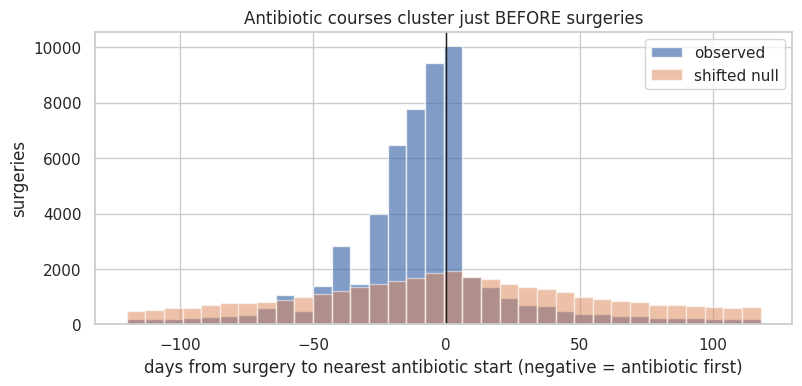

In [17]:
# ---- How are antibiotic courses and surgeries related in TIME? ----
# For every surgery: signed days to the nearest antibiotic start of the same patient (negative = antibiotic first).
a_sorted = abx[["patient_id", "start_date"]].sort_values("start_date")

obs = signed_gap(surg[["patient_id", "procedure_date"]])
# Null: move each surgery by a random +-200..700 days (keeps the patient, destroys fine timing)
rng = np.random.default_rng(1)
sh = surg[["patient_id", "procedure_date"]].copy()
sh["procedure_date"] += pd.to_timedelta(rng.integers(200, 700, len(sh)) * rng.choice([-1, 1], len(sh)), unit="D")
null = signed_gap(sh)

for lab, x in [("observed", obs), ("shifted null", null)]:
    print(f"{lab:13s}: antibiotic within +-30d of surgery: {(x.abs() <= 30).mean():.1%} | within 14d BEFORE: {x.between(-14, 0).mean():.1%} | within 14d AFTER: {x.between(1, 14).mean():.1%}")

bins = np.arange(-120, 121, 7)
plt.figure(figsize=(9, 3.8))
plt.hist(obs, bins=bins, alpha=.7, label="observed"); plt.hist(null, bins=bins, alpha=.5, label="shifted null")   # only |gap| <= 120 d is drawn
plt.axvline(0, color="k", lw=1); plt.xlabel("days from surgery to nearest antibiotic start (negative = antibiotic first)")
plt.ylabel("surgeries"); plt.legend(); plt.title("Antibiotic courses cluster just BEFORE surgeries"); plt.show()

71 % of surgeries have an antibiotic course starting within 30 days, versus 24 % under the null. Antibiotics are a flare-treatment step that usually precedes surgery. It implies recent antibiotic bursts are an indicator of surgery and high IHS4.

# 07 - time trend

In [18]:
# function helper -- general

def exposure_in_year(y):
    start, stop = pd.Timestamp(f"{y}-01-01"), min(pd.Timestamp(f"{y}-12-31"), END)
    return ((stop - pt.diagnosis_date.clip(lower=start)).dt.days.clip(lower=0) / 365.25)

def rate_by_time_since_dx(events, date_col, max_k=8):
    e = events.merge(pt[["patient_id", "diagnosis_date", "hurley_stage_baseline"]], on="patient_id")
    e["k"] = ((e[date_col] - e.diagnosis_date).dt.days // 365.25).astype(int)
    out = {}
    for h, grp in pt.groupby("hurley_stage_baseline"):
        for k in range(max_k + 1):
            exp_k = (grp.obs_years - k).clip(0, 1).sum()
            n = ((e.hurley_stage_baseline == h) & (e.k == k)).sum()
            out[(h, k)] = n / exp_k if exp_k > 20 else np.nan   # ignore thin cells
    return pd.Series(out).unstack(0)

def event_time(events, date_col):
    grid = anch.merge(pd.DataFrame({"k": ks}), how="cross")
    grid["ws"] = grid.first_bio_start + grid.k * W
    grid["ok"] = (grid.ws >= grid.diagnosis_date) & (grid.ws + W <= END)
    ev = events[["patient_id", date_col]].merge(anch[["patient_id", "first_bio_start"]], on="patient_id")
    ev["k"] = ((ev[date_col] - ev.first_bio_start) // W).astype(int)
    cnt = ev.groupby(["patient_id", "k"]).size().rename("n").reset_index()
    grid = grid.merge(cnt, how="left", on=["patient_id", "k"]).fillna({"n": 0})
    g = grid[grid.ok].groupby("k").agg(events=("n", "sum"), windows=("n", "size"))
    g["rate"] = g.events / g.windows; g["se"] = np.sqrt(g.events) / g.windows
    return g

def zero_share_models(x):
    """Observed share of zeros vs Poisson and vs Negative Binomial with the same mean & variance."""
    mu, v = x.mean(), x.var()
    nb0 = (mu / v) ** (mu ** 2 / (v - mu)) if v > mu else np.exp(-mu)
    return pd.Series(dict(mean=mu, var_over_mean=v / mu, zeros_observed=(x == 0).mean(), zeros_poisson=np.exp(-mu), zeros_negbin=nb0))

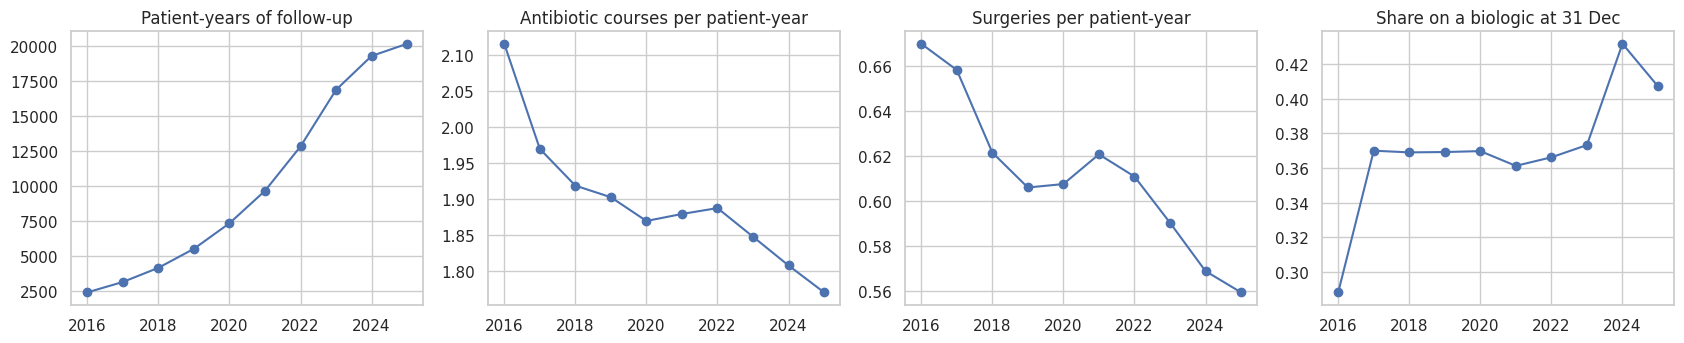

Events per patient-year by calendar year and Hurley stage:


abx              surg            
         1     2     3     1     2     3
2016 1.288 2.391 2.510 0.035 0.653 1.373
2017 1.308 2.205 2.260 0.051 0.615 1.393
2018 1.337 2.075 2.263 0.070 0.571 1.309
2019 1.340 2.057 2.244 0.057 0.532 1.351
2020 1.291 2.039 2.212 0.066 0.570 1.289
2021 1.290 2.043 2.245 0.060 0.574 1.344
2022 1.331 2.041 2.242 0.060 0.572 1.319
2023 1.287 2.019 2.186 0.050 0.559 1.280
2024 1.306 1.960 2.117 0.061 0.519 1.260
2025 1.265 1.887 2.160 0.068 0.504 1.250

In [19]:
years = range(2016, 2026)

H2 = pt[pt.hurley_stage_baseline >= 2] # only hurley 2 and 3 who gets bio
rows = []
for y in years:
    e = exposure_in_year(y); ye = pd.Timestamp(f"{y}-12-31"); y0 = pd.Timestamp(f"{y}-01-01")
    n_abx = (abx.start_date.dt.year == y).sum(); n_sur = (surg.procedure_date.dt.year == y).sum()
    at_risk = (pt.diagnosis_date <= ye)
    on = bio[(bio.start_date <= ye) & (bio.end_date.isna() | (bio.end_date > ye))].patient_id.nunique()
    # hazard of FIRST biologic start: starts / person-years still waiting for a first biologic (Hurley 2-3)
    waiting_py = ((H2.first_bio_start.fillna(END).clip(upper=min(ye, END)) - H2.diagnosis_date.clip(lower=y0)).dt.days.clip(lower=0) / 365.25).sum()
    starts = ((H2.first_bio_start >= y0) & (H2.first_bio_start <= ye)).sum()
    rows.append(dict(year=y, patients_at_risk=at_risk.sum(), patient_years=e.sum(), abx_per_py=n_abx / e.sum(),
                     surg_per_py=n_sur / e.sum(), on_biologic_at_year_end=on / at_risk.sum(), first_bio_starts_per_py_waiting=starts / waiting_py))
cal = pd.DataFrame(rows).set_index("year")

# graph
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
cal.patient_years.plot(ax=ax[0], marker="o", title="Patient-years of follow-up")
cal.abx_per_py.plot(ax=ax[1], marker="o", title="Antibiotic courses per patient-year")
cal.surg_per_py.plot(ax=ax[2], marker="o", title="Surgeries per patient-year")
cal.on_biologic_at_year_end.plot(ax=ax[3], marker="o", title="Share on a biologic at 31 Dec")
for a in ax: a.set_xlabel("")
plt.tight_layout(); plt.show()

# Is the decline just a Hurley-mix effect?  Same rates, split by baseline Hurley stage.def py_by(h, y): return exposure_in_year(y)[pt.hurley_stage_baseline == h].sum()
def py_by(h, y): return exposure_in_year(y)[pt.hurley_stage_baseline == h].sum()
by_h = pd.DataFrame({(lab, h): [ (ev[(ev.year == y)].merge(pt[["patient_id","hurley_stage_baseline"]], on="patient_id").query("hurley_stage_baseline == @h").shape[0]) / py_by(h, y) for y in years]
                     for lab, ev in [("abx", abx.assign(year=abx.start_date.dt.year)), ("surg", surg.assign(year=surg.procedure_date.dt.year))] for h in (1, 2, 3)}, index=list(years))
print("Events per patient-year by calendar year and Hurley stage:")
by_h.round(3)

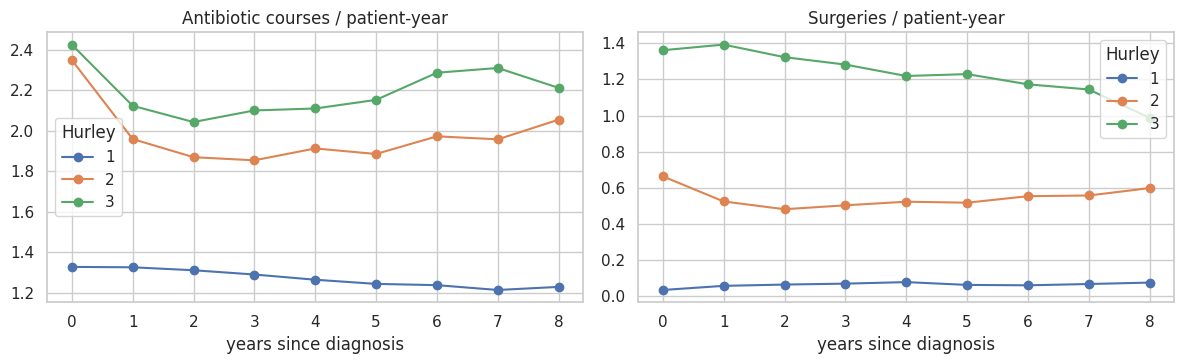

In [20]:
# Time since diagnosis (disease-duration axis), stratified by Hurley stage

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
rate_by_time_since_dx(abx, "start_date").plot(ax=ax[0], marker="o", title="Antibiotic courses / patient-year");
rate_by_time_since_dx(surg, "procedure_date").plot(ax=ax[1], marker="o", title="Surgeries / patient-year")
for a in ax: a.set_xlabel("years since diagnosis"); a.legend(title="Hurley")
plt.tight_layout(); plt.show()

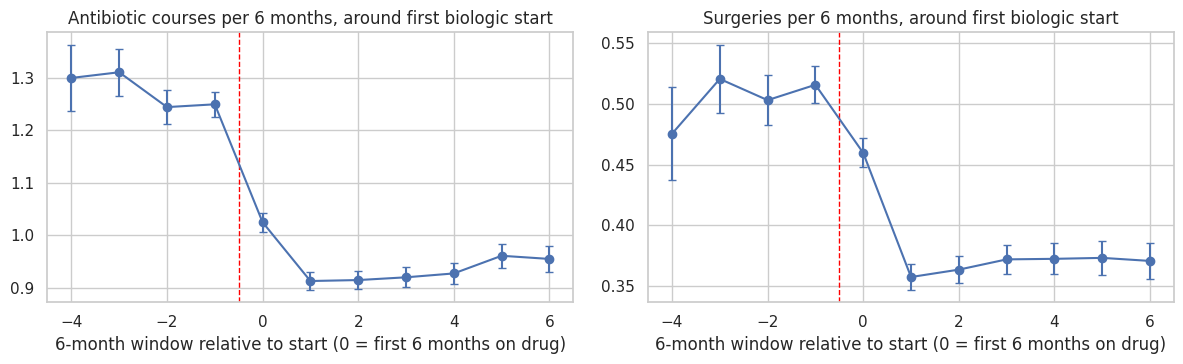

,windows_abx,rate_abx,rate_surg
k,,,
-4,1239,1.299,0.475
-3,2501,1.310,0.521
-2,4669,1.244,0.503
-1,8690,1.249,0.516
0,12514,1.025,0.460
1,12043,0.913,0.357
2,11291,0.915,0.363
3,9994,0.920,0.372
4,8615,0.927,0.372


In [21]:
# what happens around the START of the first biologic?
# Windows of ~6 months relative to the start date

W = pd.Timedelta(days=182)
anch = pt.loc[pt.first_bio_start.notna(), ["patient_id", "first_bio_start", "diagnosis_date"]]
ks = np.arange(-4, 7)

# graph
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (ev, col, name) in zip(ax, [(abx, "start_date", "Antibiotic courses"), (surg, "procedure_date", "Surgeries")]):
    g = event_time(ev, col)
    a.errorbar(g.index, g.rate, yerr=1.96 * g.se, marker="o", capsize=3)
    a.axvline(-0.5, color="red", ls="--", lw=1); a.set_title(f"{name} per 6 months, around first biologic start")
    a.set_xlabel("6-month window relative to start (0 = first 6 months on drug)")

plt.tight_layout(); plt.show()
event_time(abx, "start_date").join(event_time(surg, "procedure_date"), lsuffix="_abx", rsuffix="_surg")[["windows_abx", "rate_abx", "rate_surg"]]

Analysable first-line patients: 2478  (all still on drug at month 18 -> early quitters are excluded by construction)
        mean  var_over_mean  zeros_observed  zeros_poisson  zeros_negbin  excess_vs_negbin
2 pre  3.307          1.721           0.082          0.037         0.083            -0.001
  post 2.121          1.920           0.208          0.120         0.222            -0.014
3 pre  3.989          1.890           0.073          0.019         0.058             0.015
  post 3.231          2.057           0.116          0.040         0.110             0.005


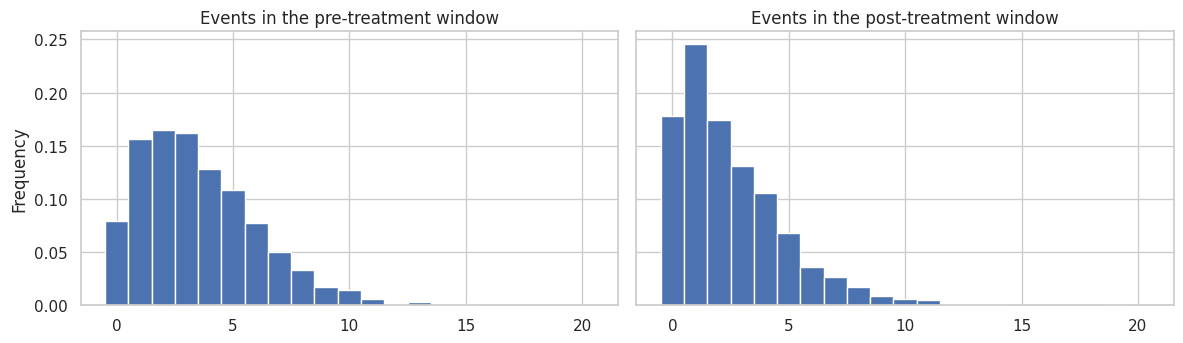

In [22]:
# indication for treatment response
# If a subgroup of 'super-responders' exists, their flare-related activity (antibiotic courses + surgeries) should be near ZERO after the drug has had time to work -- more often than a smooth patient-to-patient spread predicts.
R = pt[pt.first_bio_start.notna()].copy()
ev_all = pd.concat([abx[["patient_id", "start_date"]].rename(columns={"start_date": "d"}),
                    surg[["patient_id", "procedure_date"]].rename(columns={"procedure_date": "d"})])
m = ev_all.merge(R[["patient_id", "first_bio_start"]], on="patient_id")
m["rel"] = (m.d - m.first_bio_start).dt.days
def window_count(lo, hi):
    return m[(m.rel >= lo) & (m.rel < hi)].groupby("patient_id").size().reindex(R.patient_id).fillna(0).values
R["pre"]  = window_count(-365, 0)       # 12 months before the first biologic
R["post"] = window_count(180, 545)      # months 6-18 on drug (ramp-up skipped)

line1_end = bio[bio.treatment_line == 1].set_index("patient_id").end_date
R["l1_end"] = R.patient_id.map(line1_end)
ok = (R.first_bio_start - pd.Timedelta(days=365) >= R.diagnosis_date) & (R.first_bio_start + pd.Timedelta(days=545) <= END) \
     & (R.l1_end.isna() | (R.l1_end >= R.first_bio_start + pd.Timedelta(days=545)))
S = R[ok & (R.hurley_stage_baseline >= 2)].copy()
print(f"Analysable first-line patients: {len(S)}  (all still on drug at month 18 -> early quitters are excluded by construction)")

tab = pd.concat({(h, w): zero_share_models(g[w]) for h, g in S.groupby("hurley_stage_baseline") for w in ["pre", "post"]}, axis=1).T
tab["excess_vs_negbin"] = tab.zeros_observed - tab.zeros_negbin
print(tab.round(3).to_string())

# graph
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a, col in zip(ax, ["pre", "post"]):
    S[col].clip(upper=20).plot.hist(bins=np.arange(-.5, 21), ax=a, density=True); a.set_title(f"Events in the {col}-treatment window")
plt.tight_layout(); plt.show()

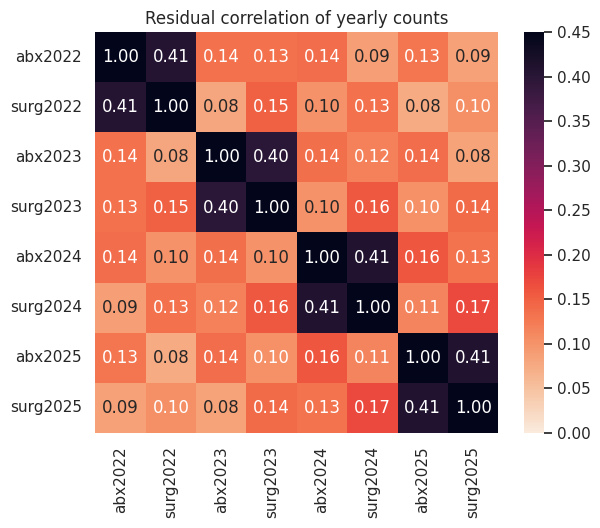

abx vs surgery, SAME year: 0.41 | abx -> abx next year: 0.14 | surgery -> surgery next year: 0.16 | abx -> surgery next year: 0.13


In [23]:
# Is there a stable patient-level 'activity' trait beyond Hurley stage? 
# Use patients diagnosed before 2022 so that all of 2022-2025 is observed. Residualise on Hurley stage, then correlate years.
P = pt[pt.diagnosis_date < "2022-01-01"].copy()
cols = []
for y in [2022, 2023, 2024, 2025]:
    P[f"abx{y}"] = P.patient_id.map(abx[abx.start_date.dt.year == y].groupby("patient_id").size()).fillna(0)
    P[f"surg{y}"] = P.patient_id.map(surg[surg.procedure_date.dt.year == y].groupby("patient_id").size()).fillna(0)
    cols += [f"abx{y}", f"surg{y}"]
R_ = P[cols] - P.groupby("hurley_stage_baseline")[cols].transform("mean")      

# residual after Hurley mean
corr = R_.corr()
plt.figure(figsize=(6.5, 5.2)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=.45); plt.title("Residual correlation of yearly counts"); plt.show()

same_year = np.mean([corr.loc[f"abx{y}", f"surg{y}"] for y in range(2022, 2026)])
abx_cross = np.mean([corr.loc[f"abx{y}", f"abx{y+1}"] for y in range(2022, 2025)])
surg_cross = np.mean([corr.loc[f"surg{y}", f"surg{y+1}"] for y in range(2022, 2025)])
mix_cross = np.mean([corr.loc[f"abx{y}", f"surg{y+1}"] for y in range(2022, 2025)])
print(f"abx vs surgery, SAME year: {same_year:.2f} | abx -> abx next year: {abx_cross:.2f} | surgery -> surgery next year: {surg_cross:.2f} | abx -> surgery next year: {mix_cross:.2f}")

# 08 -- practicioners

In [24]:
# function helper -- analysis

def z_sd(obs, exp, var, labels):
    O = np.bincount(labels, obs); E = np.bincount(labels, exp); V = np.bincount(labels, var)
    keep = V > 0
    return ((O - E)[keep] / np.sqrt(V[keep])).std()

def test_metric(name, obs, exp, var, n_perm=300, surgery_level_idx=None):
    obs, exp, var = map(np.asarray, (obs, exp, var))
    # surgery-level metrics: practitioner label is inherited from the patient, so permute PATIENT labels, then look them up.
    lab = (lambda c: c[surgery_level_idx]) if surgery_level_idx is not None else (lambda c: c)
    sd = z_sd(obs, exp, var, lab(codes))
    null = np.array([z_sd(obs, exp, var, lab(rng.permutation(codes))) for _ in range(n_perm)])
    return dict(metric=name, observed_SD_of_z=sd, chance_mean=null.mean(), chance_95pct_max=np.quantile(null, .95),
                beyond_chance=sd > np.quantile(null, .999))

def prac_corr(labels, min_n=10):
    n = np.bincount(labels); s = np.bincount(labels, pt.surg_resid) / np.maximum(n, 1); a = np.bincount(labels, pt.abx_resid) / np.maximum(n, 1)
    k = n >= min_n; return stats.spearmanr(s[k], a[k])[0]


In [25]:
# Practitioner effects: is variation between practitioners bigger than chance?
# For each practitioner: z = (observed - expected) / sqrt(variance), with "expected" from the patient's own stratum.
# If practitioners were interchangeable, SD(z) would be ~1 for pure Poisson/Bernoulli noise -- BUT real counts are
# overdispersed (var/mean = 2-4, see surgery section), which inflates SD(z) even with no practitioner effect.
# So we calibrate "what SD(z) does chance give?" by a permutation test: shuffle practitioner labels across patients.
rng = np.random.default_rng(0)
codes = pd.factorize(pt.practitioner_id)[0]

res = []
for col, label, strata in [("n_surg", "surgeries (given Hurley)", ["hurley_stage_baseline"]),
                           ("n_abx", "antibiotic courses (given Hurley, biologic status)", ["hurley_stage_baseline", "bio_status"])]:
    rate = pt.groupby(strata)[col].transform("sum") / pt.groupby(strata).exposure.transform("sum")
    exp = rate * pt.exposure
    res.append(test_metric(label, pt[col], exp, exp))
p = pt.groupby("hurley_stage_baseline").on_bio.transform("mean")
res.append(test_metric("on biologic (given Hurley)", pt.on_bio.astype(float), p, p * (1 - p)))
for f in ["bmi_at_baseline", "symptom_onset_date", "smoking_status", "family_history_hs", "ethnicity"]:
    m = pt[f].isna().astype(float); p0 = m.mean()
    res.append(test_metric(f"{f} missing", m, np.full(len(pt), p0), np.full(len(pt), p0 * (1 - p0))))

# surgery-level: is a surgery logged against a visit?  (probability depends on calendar year)
pidx = surg.patient_id.map(dict(zip(pt.patient_id, range(len(pt))))).values
py_ = surg.groupby("year").visit_id.transform(lambda x: x.notna().mean()).values
res.append(test_metric("surgery has a visit_id (given year)", surg.visit_id.notna().astype(float).values, py_, py_ * (1 - py_), surgery_level_idx=pidx))
pract_tab = pd.DataFrame(res).set_index("metric")
pract_tab

,observed_SD_of_z,chance_mean,chance_95pct_max,beyond_chance
metric,,,,
surgeries (given Hurley),1.582,1.583,1.620,False
"antibiotic courses (given Hurley, biologic status)",1.354,1.379,1.413,False
on biologic (given Hurley),1.026,1.001,1.023,False
bmi_at_baseline missing,1.016,0.999,1.027,False
symptom_onset_date missing,0.998,0.999,1.019,False
smoking_status missing,1.021,1.000,1.027,False
family_history_hs missing,0.982,0.999,1.023,False
ethnicity missing,1.014,1.000,1.025,False
surgery has a visit_id (given year),1.293,1.307,1.335,False


In [26]:
# Is there a shared practitioner habit? Careful: patient-level correlation alone already creates a correlation between practitioner means, so we compare with a permutation null.
rate_s = pt.groupby("hurley_stage_baseline").n_surg.transform("sum") / pt.groupby("hurley_stage_baseline").exposure.transform("sum")
strata = ["hurley_stage_baseline", "bio_status"]
rate_a = pt.groupby(strata).n_abx.transform("sum") / pt.groupby(strata).exposure.transform("sum")
pt["surg_resid"] = pt.n_surg - rate_s * pt.exposure
pt["abx_resid"]  = pt.n_abx  - rate_a * pt.exposure
print(f"PATIENT-level correlation of surgery and antibiotic residuals: {np.corrcoef(pt.surg_resid, pt.abx_resid)[0, 1]:.2f}")

obs_r = prac_corr(codes)
null_r = np.array([prac_corr(rng.permutation(codes)) for _ in range(300)])
print(f"PRACTITIONER-level Spearman (>=10 patients): observed {obs_r:.2f} | chance (shuffled labels) {null_r.mean():.2f} +- {null_r.std():.2f}")
ps = pt.groupby("practitioner_id").size()
print("Patients per practitioner:", ps.describe().round(1).to_dict())

PATIENT-level correlation of surgery and antibiotic residuals: 0.52
PRACTITIONER-level Spearman (>=10 patients): observed 0.50 | chance (shuffled labels) 0.49 +- 0.02
Patients per practitioner: {'count': 2136.0, 'mean': 9.8, 'std': 5.4, 'min': 1.0, '25%': 5.0, '50%': 9.0, '75%': 14.0, 'max': 24.0}


# 09 -- subpopulations

Silhouette by k (>0.5 = clear clusters, <0.25 = mostly a continuum):
2   0.397
3   0.312
4   0.296
5   0.301
6   0.295
7   0.297
8   0.294

Chosen k = 2


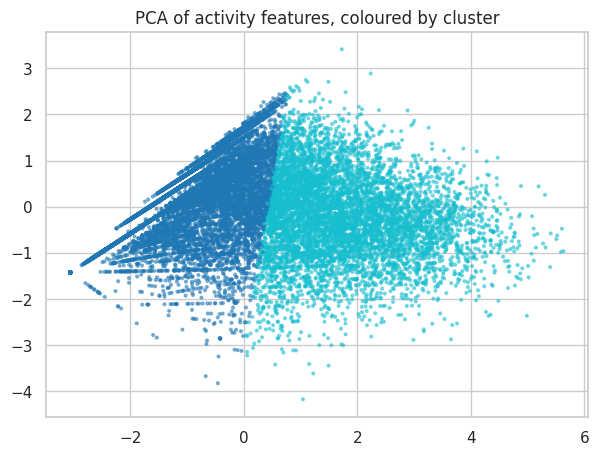

,n,hurley,on_bio,ever_bio,abx_rate,surg_rate,abx_12m,surg_12m,obs_years,bmi,female,age_dx
cluster,,,,,,,,,,,,
0,12574,1.681,0.396,0.539,1.443,0.208,1.183,0.052,5.127,31.260,0.689,29.097
1,6709,2.469,0.465,0.872,2.589,1.309,2.821,1.502,5.378,32.588,0.777,27.935


In [27]:
# Unsupervised look for sub-populations
# Features: long-run and recent activity.  Use log1p because counts are skewed. Require >= 2 years of follow-up.
sub = pt[pt.obs_years >= 2].copy()
feats = ["abx_rate", "surg_rate", "n_abx_12m", "n_surg_12m"]
X = StandardScaler().fit_transform(np.log1p(sub[feats]))

sil = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X), sample_size=6000, random_state=0) for k in range(2, 9)}
print("Silhouette by k (>0.5 = clear clusters, <0.25 = mostly a continuum):")
print(pd.Series(sil).round(3).to_string())

k = max(sil, key=sil.get)
sub["cluster"] = KMeans(k, n_init=10, random_state=0).fit_predict(X)
prof = sub.groupby("cluster").agg(n=("patient_id", "size"), hurley=("hurley_stage_baseline", "mean"),
        on_bio=("on_bio", "mean"), ever_bio=("ever_bio", "mean"), abx_rate=("abx_rate", "mean"), surg_rate=("surg_rate", "mean"),
        abx_12m=("n_abx_12m", "mean"), surg_12m=("n_surg_12m", "mean"), obs_years=("obs_years", "mean"),
        bmi=("bmi_at_baseline", "mean"), female=("sex", lambda x: (x == "Female").mean()), age_dx=("age_at_diagnosis", "mean"))

print(f"\nChosen k = {k}");
Z = PCA(2, random_state=0).fit_transform(X)
plt.figure(figsize=(7, 5)); plt.scatter(Z[:, 0], Z[:, 1], c=sub.cluster, s=4, cmap="tab10", alpha=.5)
plt.title("PCA of activity features, coloured by cluster"); plt.show()
prof

Silhouette is **0.40 at k = 2 and a flat ~0.30 for every k from 3 to 8**: one dominant split, then a continuous. The split is a **surgical-activity / severity axis**: cluster 1 (n = 6,709) averages 1.31 surgeries and 2.6 antibiotic courses per year, mean Hurley 2.5; cluster 0 (n = 12,574) 0.21 and 1.4, Hurley 1.7. The diagonal streaks in the PCA plot are just the discreteness of small counts. There is no hidden subtype visible from treatment activity alone.

In [28]:
# Rule-based segments: more interpretable than clusters when the data has hard rules
pt["segment"] = np.select(
    [pt.hurley_stage_baseline == 1,
     pt.bio_status == "never biologic",
     pt.bio_status == "stopped biologic",
     pt.n_bio_lines >= 2,
     pt.days_on_cur < 365],
    ["A. Hurley 1 (no biologic)", "B. Hurley 2-3, never biologic", "C. Hurley 2-3, stopped biologic",
     "D. On biologic, switched >=1 time", "E. On first biologic <1 year"],
    "F. On first biologic >=1 year")
seg = pt.groupby("segment").agg(n=("patient_id", "size"), share=("patient_id", lambda x: len(x) / len(pt)),
        hurley3=("hurley_stage_baseline", lambda x: (x == 3).mean()), abx_rate=("abx_rate", "mean"), surg_rate=("surg_rate", "mean"),
        abx_12m=("n_abx_12m", "mean"), surg_12m=("n_surg_12m", "mean"), obs_years=("obs_years", "mean"))
seg

,n,share,hurley3,abx_rate,surg_rate,abx_12m,surg_12m,obs_years
segment,,,,,,,,
A. Hurley 1 (no biologic),6280,0.299,0.000,1.287,0.054,1.200,0.065,4.666
"B. Hurley 2-3, never biologic",1620,0.077,0.351,2.343,0.892,1.899,0.756,4.448
"C. Hurley 2-3, stopped biologic",4552,0.217,0.360,2.230,0.909,2.308,0.941,6.158
"D. On biologic, switched >=1 time",1786,0.085,0.392,2.107,0.904,1.918,0.793,5.288
E. On first biologic <1 year,1015,0.048,0.338,2.420,0.909,1.945,0.754,1.821
F. On first biologic >=1 year,5747,0.274,0.331,1.830,0.667,1.596,0.553,4.467


In [29]:
# Unusual individuals 
print("Patients with NO treatment record at all:", (pt.n_abx + pt.n_bio_lines == 0).sum(),
      "| of which Hurley 1:", ((pt.n_abx + pt.n_bio_lines == 0) & (pt.hurley_stage_baseline == 1)).sum())
print("First-line biologic is NOT adalimumab:", (first.drug_name != "Adalimumab").sum(), "patients")
print("Three biologic lines:", (pt.n_bio_lines == 3).sum(), "| of which on a biologic now:", ((pt.n_bio_lines == 3) & pt.on_bio).sum())
hi = pt.surg_rate.rank(pct=True) > .99
print(f"\nTop 1% surgery rate (n={hi.sum()}): Hurley mix", pt[hi].hurley_stage_baseline.value_counts(normalize=True).round(2).to_dict(),
      "| biologic share", pt[hi].on_bio.mean().round(2), "vs cohort", pt.on_bio.mean().round(2))
print("Median days since last treatment event, by Hurley:")

last = pd.concat([abx.groupby("patient_id").start_date.max(), surg.groupby("patient_id").procedure_date.max()], axis=1).max(axis=1)
pt["days_since_last_event"] = (END - pt.patient_id.map(last)).dt.days
pt.groupby("hurley_stage_baseline").days_since_last_event.describe()[["count", "25%", "50%", "75%", "max"]]

Patients with NO treatment record at all: 706 | of which Hurley 1: 466
First-line biologic is NOT adalimumab: 13 patients
Three biologic lines: 622 | of which on a biologic now: 350

Top 1% surgery rate (n=210): Hurley mix {3: 0.71, 2: 0.28, 1: 0.0} | biologic share 0.59 vs cohort 0.41
Median days since last treatment event, by Hurley:


,count,25%,50%,75%,max
hurley_stage_baseline,,,,,
1,"5,817.000",75.000,184.000,381.000,"2,711.000"
2,"9,318.000",49.000,128.000,274.000,"2,450.000"
3,"5,034.000",36.000,95.000,201.000,"2,046.000"


# 10 -- pair with target in train data set

Targets: (21000, 2) | missing: 0 | duplicate ids: 0


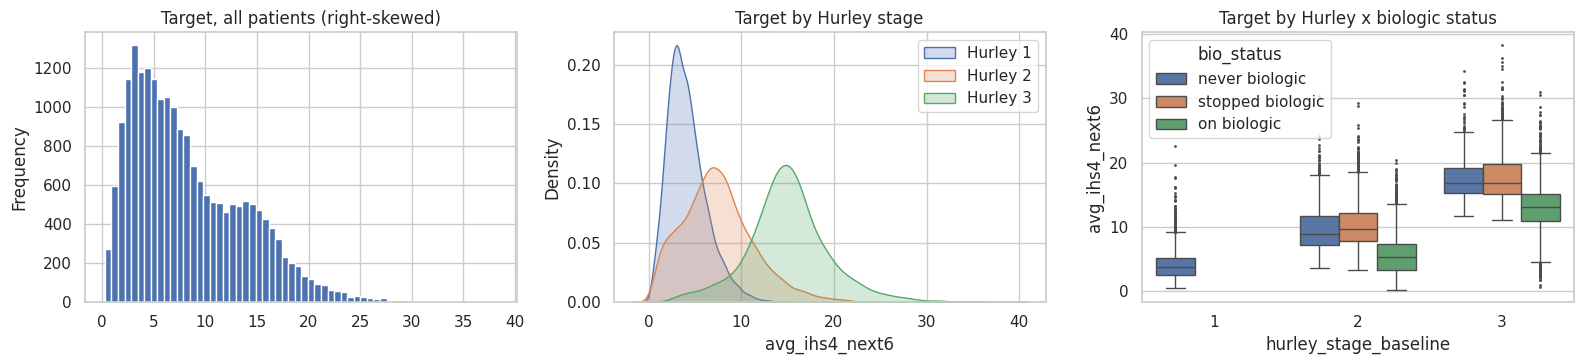

{'count': 21000.0, 'mean': 8.32, 'std': 5.45, 'min': 0.27, '25%': 3.98, '50%': 6.98, '75%': 12.0, 'max': 38.34}


n   mean  median    sd
hurley_stage_baseline bio_status                                 
1                     never biologic    6280  4.140   3.788 2.163
2                     never biologic    1051  9.804   8.937 3.490
                      on biologic       5602  5.566   5.344 2.980
                      stopped biologic  2912 10.269   9.656 3.412
3                     never biologic     569 17.668  16.874 3.493
                      on biologic       2946 12.913  13.080 3.791
                      stopped biologic  1640 17.823  16.882 3.702

In [30]:
# targets.csv: avg_ihs4_next6
Y = "avg_ihs4_next6"
tg = pd.read_csv(BASE + "targets.csv")

# idempotent merge: remove any previous copy (and _x/_y leftovers) of the target
pt = pt.drop(columns=[c for c in pt.columns if c.startswith(Y)], errors="ignore")
pt = pt.merge(tg, on="patient_id", how="left")

print("Targets:", tg.shape, "| missing:", pt[Y].isna().sum(), "| duplicate ids:", tg.patient_id.duplicated().sum())

# graph
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
pt[Y].plot.hist(bins=60, ax=ax[0]); ax[0].set_title("Target, all patients (right-skewed)")
for h, g in pt.groupby("hurley_stage_baseline"): sns.kdeplot(g[Y], ax=ax[1], label=f"Hurley {h}", fill=True, alpha=.25)
ax[1].set_title("Target by Hurley stage"); ax[1].legend()
sns.boxplot(data=pt, x="hurley_stage_baseline", y=Y, hue="bio_status", ax=ax[2], fliersize=1); ax[2].set_title("Target by Hurley x biologic status")
plt.tight_layout(); plt.show()
print(pt[Y].describe().round(2).to_dict())
pt.groupby(["hurley_stage_baseline", "bio_status"])[Y].agg(n="size", mean="mean", median="median", sd="std")

In [32]:
# (from the "diagnosis-date oddities" cell) first treatment event after diagnosis + prevalent-cohort flag
pt["first_evt"] = pd.concat([abx[["patient_id", "start_date"]].rename(columns={"start_date": "d"}),
                             surg[["patient_id", "procedure_date"]].rename(columns={"procedure_date": "d"})]
                            ).groupby("patient_id").d.min().reindex(pt.patient_id).values
pt["first_evt_days"] = (pt.first_evt - pt.diagnosis_date).dt.days
pt["prevalent"] = pt.diagnosis_date == pd.Timestamp("2016-01-02")

# (from the "edge cases" cell) days since the last antibiotic course or surgery
last = pd.concat([abx.groupby("patient_id").start_date.max(),
                  surg.groupby("patient_id").procedure_date.max()], axis=1).max(axis=1)
pt["days_since_last_event"] = (END - pt.patient_id.map(last)).dt.days

In [33]:
# Which descriptors relate to the target?  Spearman for numbers (overall and WITHIN Hurley stage), Kruskal-Wallis for categories.
num = ["n_surg", "surg_rate", "n_surg_12m", "n_abx", "abx_rate", "n_abx_12m", "n_bio_lines", "obs_years", "days_on_cur",
       "first_evt_days", "diagnostic_delay_years", "bmi_at_baseline", "age_at_diagnosis", "days_since_last_event"]
rows = []
for c in num:
    d = pt[[c, Y, "hurley_stage_baseline"]].dropna()
    within = np.mean([stats.spearmanr(g[c], g[Y])[0] for _, g in d.groupby("hurley_stage_baseline")])
    rows.append((c, stats.spearmanr(d[c], d[Y])[0], within))
num_tab = pd.DataFrame(rows, columns=["feature", "spearman_overall", "spearman_within_hurley"]).set_index("feature").sort_values("spearman_within_hurley", key=abs, ascending=False)

rows = []
for c in ["sex", "ethnicity", "smoking_status", "family_history_hs", "bio_status", "cur_drug", "prevalent", "practitioner_id"]:
    d = pt[[c, Y]].copy(); d[c] = d[c].fillna("missing")
    groups = [g[Y].values for _, g in d.groupby(c) if len(g) >= 5]
    H = stats.kruskal(*groups).statistic; eta = max(0, (H - len(groups) + 1) / (len(d) - len(groups)))   # epsilon-squared effect size
    rows.append((c, len(groups), eta, stats.kruskal(*groups).pvalue))
cat_tab = pd.DataFrame(rows, columns=["feature", "groups", "effect_size_eps2", "p"]).set_index("feature")
print("Numeric features:"); print(num_tab.round(3).to_string()); print("\nCategorical features (effect size eps^2: 0.01 small, 0.06 medium, 0.14 large):")
cat_tab.round(4)

Numeric features:
                        spearman_overall  spearman_within_hurley
feature                                                         
n_surg                             0.683                   0.364
surg_rate                          0.679                   0.316
n_surg_12m                         0.565                   0.309
n_abx                              0.362                   0.281
abx_rate                           0.395                   0.233
n_abx_12m                          0.319                   0.233
days_since_last_event             -0.308                  -0.227
obs_years                          0.146                   0.179
days_on_cur                       -0.074                  -0.087
bmi_at_baseline                    0.028                   0.024
age_at_diagnosis                  -0.000                  -0.016
diagnostic_delay_years             0.010                   0.012
first_evt_days                    -0.146                  -0.010
n_bio_l

,groups,effect_size_eps2,p
feature,,,
sex,2,0.003,0.000
ethnicity,6,0.001,0.001
smoking_status,4,0.000,0.385
family_history_hs,4,0.000,0.161
bio_status,3,0.257,0.000
cur_drug,4,0.009,0.000
prevalent,2,0.008,0.000
practitioner_id,1690,0.001,0.428


In [34]:
# Prevalent (2016-01-02) patients have a higher raw target. Is that real, or just that more of them stopped their biologic?
g = pt.groupby(["hurley_stage_baseline", "bio_status"])[Y]
pt["resid_vs_group_mean"] = pt[Y] - g.transform("mean")
print("Raw target:     ", pt.groupby("prevalent")[Y].mean().round(2).to_dict())
print("After Hurley x biologic-status adjustment (mean residual):", pt.groupby("prevalent").resid_vs_group_mean.mean().round(3).to_dict())
print("Sex gap raw:", pt.groupby("sex")[Y].mean().round(2).to_dict(), "| adjusted:", pt.groupby("sex").resid_vs_group_mean.mean().round(3).to_dict())

Raw target:      {False: 8.16, True: 9.82}
After Hurley x biologic-status adjustment (mean residual): {False: -0.035, True: 0.319}
Sex gap raw: {'Female': 8.51, 'Male': 7.83} | adjusted: {'Female': 0.188, 'Male': -0.482}


                                            MAE  gain_vs_mean_%
population mean                           4.453           0.000
population median                         4.334           2.676
Hurley-stage median                       2.667          40.124
Hurley x biologic-status median           2.297          48.432
GBM, all tabular features (5-fold CV)     2.018          54.686
GBM, activity + biologic only (5-fold CV) 2.025          54.519


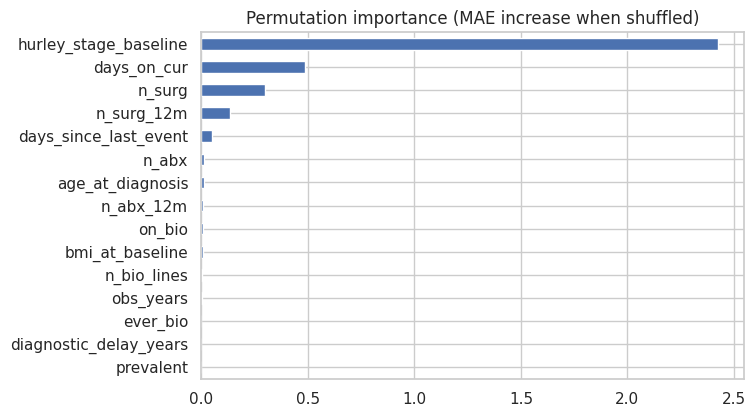

In [35]:
# Baselines the jury lists (population mean, Hurley-stage mean) + stronger tabular models; all scored by MAE
mae = lambda a, b: float(np.mean(np.abs(a - b)))

res = {"population mean": mae(pt[Y], pt[Y].mean()), "population median": mae(pt[Y], pt[Y].median()),
       "Hurley-stage median": mae(pt[Y], pt.groupby("hurley_stage_baseline")[Y].transform("median")),
       "Hurley x biologic-status median": mae(pt[Y], pt.groupby(["hurley_stage_baseline", "bio_status"])[Y].transform("median"))}

feat = ["hurley_stage_baseline", "on_bio", "ever_bio", "n_bio_lines", "days_on_cur", "n_abx", "n_abx_12m", "n_surg", "n_surg_12m",
        "days_since_last_event", "obs_years", "age_at_diagnosis", "bmi_at_baseline", "diagnostic_delay_years", "prevalent"]
X = pt[feat].astype(float)
gbm = lambda: HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=.05, random_state=0)
res["GBM, all tabular features (5-fold CV)"] = mae(pt[Y], cross_val_predict(gbm(), X, pt[Y], cv=KFold(5, shuffle=True, random_state=0)))
core = ["hurley_stage_baseline", "on_bio", "ever_bio", "n_bio_lines", "days_on_cur", "n_abx", "n_abx_12m", "n_surg", "n_surg_12m", "days_since_last_event"]
res["GBM, activity + biologic only (5-fold CV)"] = mae(pt[Y], cross_val_predict(gbm(), pt[core].astype(float), pt[Y], cv=KFold(5, shuffle=True, random_state=0)))
base_tab = pd.Series(res, name="MAE").to_frame(); base_tab["gain_vs_mean_%"] = 100 * (1 - base_tab.MAE / base_tab.MAE.iloc[0])
print(base_tab.round(3).to_string())

# What does the model lean on?  Permutation importance on a held-out 25 %
Xtr, Xte, ytr, yte = train_test_split(X, pt[Y], test_size=.25, random_state=0)
m = gbm().fit(Xtr, ytr)
pi = permutation_importance(m, Xte, yte, scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=feat).sort_values()
imp.plot.barh(figsize=(7, 4.5), title="Permutation importance (MAE increase when shuffled)"); plt.show()

Reference (non-biologic) mean target by Hurley: {1: 4.14, 2: 10.15, 3: 17.78}


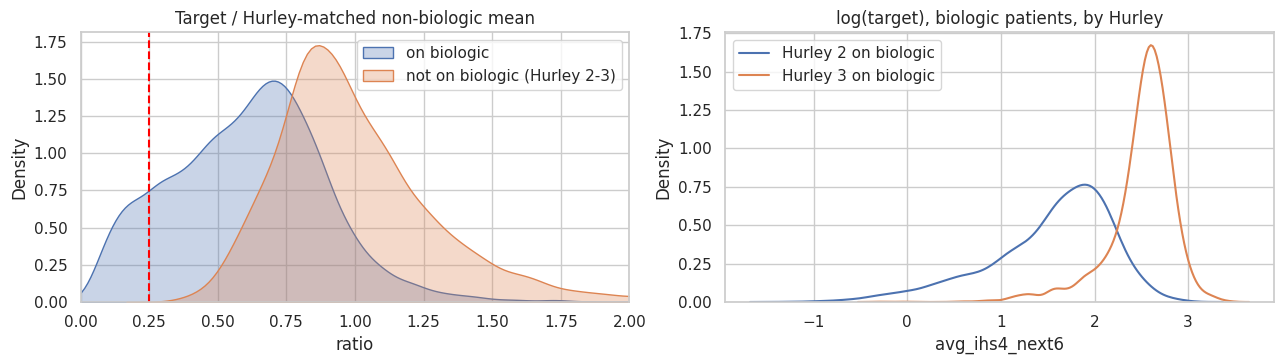

                       on_biologic_share_below_0.25  not_on_biologic_share_below_0.25
hurley_stage_baseline                                                                
2                                             0.168                             0.000
3                                             0.022                             0.000 
Overall on-biologic share below 0.25: 11.8%  (brief: roughly 1 in 8 = 12.5 %)


,hurley,components,BIC,means_back_transformed,weights
0,2,1,"11,193.445",[4.66],[1.0]
1,2,2,"10,182.997","[6.3, 2.21]","[0.71, 0.29]"
2,2,3,"10,199.050","[7.28, 3.99, 1.57]","[0.51, 0.33, 0.16]"
3,3,1,"2,336.829",[12.23],[1.0]
4,3,2,"1,318.990","[13.52, 7.17]","[0.84, 0.16]"
5,3,3,"1,333.675","[14.39, 11.82, 7.49]","[0.53, 0.31, 0.15]"


In [36]:
# Biologic subgroup & super-responders (target-based) 
# Super-responder (brief): IHS4 > 75 % below what it would have been without treatment. We never see that counterfactual, so use a proxy: ratio = target / mean target of NON-biologic patients with the same Hurley stage. Ratio < 0.25 ~ "75 % below".
ref = pt[pt.bio_status != "on biologic"].groupby("hurley_stage_baseline")[Y].mean()
pt["ratio"] = pt[Y] / pt.hurley_stage_baseline.map(ref)
bio_on = pt[pt.on_bio].copy(); nonbio = pt[(~pt.on_bio) & (pt.hurley_stage_baseline >= 2)]
print("Reference (non-biologic) mean target by Hurley:", ref.round(2).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.kdeplot(bio_on.ratio, ax=ax[0], label="on biologic", fill=True, alpha=.3); sns.kdeplot(nonbio.ratio, ax=ax[0], label="not on biologic (Hurley 2-3)", fill=True, alpha=.3)
ax[0].axvline(.25, color="red", ls="--"); ax[0].set_xlim(0, 2); ax[0].set_title("Target / Hurley-matched non-biologic mean"); ax[0].legend()
for h, g in bio_on.groupby("hurley_stage_baseline"): sns.kdeplot(np.log(g[Y]), ax=ax[1], label=f"Hurley {h} on biologic")
ax[1].set_title("log(target), biologic patients, by Hurley"); ax[1].legend()
plt.tight_layout(); plt.show()

tab = pd.DataFrame({"on_biologic_share_below_0.25": bio_on.groupby("hurley_stage_baseline").ratio.apply(lambda x: (x < .25).mean()),
                    "not_on_biologic_share_below_0.25": nonbio.groupby("hurley_stage_baseline").ratio.apply(lambda x: (x < .25).mean())})
print(tab.round(3).to_string(), f"\nOverall on-biologic share below 0.25: {(bio_on.ratio < .25).mean():.1%}  (brief: roughly 1 in 8 = 12.5 %)")

# Is the distribution a smooth single bump or a MIXTURE?  Gaussian mixtures on log(target); lower BIC = better.
from sklearn.mixture import GaussianMixture
rows = []
for h, g in bio_on.groupby("hurley_stage_baseline"):
    x = np.log(g[Y].values).reshape(-1, 1)
    for k in (1, 2, 3):
        gm = GaussianMixture(k, n_init=3, random_state=0).fit(x)
        rows.append(dict(hurley=h, components=k, BIC=gm.bic(x), means_back_transformed=np.exp(gm.means_.ravel()).round(2).tolist(), weights=gm.weights_.round(2).tolist()))
pd.DataFrame(rows)

In [37]:
# What separates super-responders, and could it be seen BEFORE or EARLY in treatment?
# Features are built relative to the START of the current biologic line, using only events before the cut-off.
cur = bio[bio.end_date.isna()].set_index("patient_id")
b = bio_on.copy(); b["sr"] = b.ratio < .25
b["line_start"] = b.patient_id.map(cur.start_date)
ev = pd.concat([abx[["patient_id", "start_date"]].rename(columns={"start_date": "d"}).assign(t="a"),
                surg[["patient_id", "procedure_date"]].rename(columns={"procedure_date": "d"}).assign(t="s")])
m = ev.merge(b[["patient_id", "line_start"]], on="patient_id"); m["rel"] = (m.d - m.line_start).dt.days
def cnt(lo, hi, t, name): b[name] = b.patient_id.map(m[(m.rel >= lo) & (m.rel < hi) & (m.t == t)].groupby("patient_id").size()).fillna(0)
cnt(-365, 0, "a", "pre_abx_12m"); cnt(-365, 0, "s", "pre_surg_12m"); cnt(-730, -365, "a", "pre_abx_prev12m")
cnt(0, 180, "a", "early_abx_6m"); cnt(0, 180, "s", "early_surg_6m")
b["start_after_dx_days"] = (b.line_start - b.diagnosis_date).dt.days

# keep patients whose first 6 months on drug AND the 12 months before it are observed
sub = b[(b.days_on_cur >= 180) & (b.line_start - pd.Timedelta(days=365) >= b.diagnosis_date)].copy()
print(f"n = {len(sub)}, super-responder share = {sub.sr.mean():.1%}")
cmp_cols = ["pre_abx_12m", "pre_surg_12m", "early_abx_6m", "early_surg_6m", "start_after_dx_days", "n_bio_lines", "age_at_diagnosis", "bmi_at_baseline", "diagnostic_delay_years"]
print(sub.groupby("sr")[cmp_cols].mean().round(2).T.to_string())
print("\nSuper-responder share by category:")
for c in ["hurley_stage_baseline", "n_bio_lines", "cur_drug", "sex", "smoking_status", "family_history_hs", "ethnicity", "prevalent"]:
    print(f"  {c:22s}", sub.groupby(c, dropna=False).sr.mean().round(3).to_dict())

# Can a model tell them apart? Cross-validated AUC with feature sets of increasing information (0.5 = coin flip)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
demo_f = ["hurley_stage_baseline", "age_at_diagnosis", "bmi_at_baseline", "diagnostic_delay_years"]
pre_f = demo_f + ["pre_abx_12m", "pre_surg_12m", "pre_abx_prev12m", "start_after_dx_days", "n_bio_lines"]
early_f = pre_f + ["early_abx_6m", "early_surg_6m"]
out = {}
for name, f in [("demographics + Hurley", demo_f), ("+ pre-treatment history", pre_f), ("+ first 6 months on drug", early_f)]:
    p = cross_val_predict(HistGradientBoostingClassifier(max_iter=200, learning_rate=.05, random_state=0), sub[f].astype(float), sub.sr,
                          cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    out[name] = roc_auc_score(sub.sr, p)
pd.Series(out, name="CV AUC").round(3)

n = 3753, super-responder share = 8.1%
sr                       False   True 
pre_abx_12m              2.390   2.370
pre_surg_12m             1.020   0.850
early_abx_6m             1.020   0.760
early_surg_6m            0.480   0.170
start_after_dx_days    826.330 592.790
n_bio_lines              1.470   1.100
age_at_diagnosis        28.330  26.740
bmi_at_baseline         32.010  30.620
diagnostic_delay_years   4.150   3.660

Super-responder share by category:
  hurley_stage_baseline  {2: 0.112, 3: 0.021}
  n_bio_lines            {1: 0.116, 2: 0.025, 3: 0.004}
  cur_drug               {'Adalimumab': 0.116, 'Bimekizumab': 0.023, 'Secukinumab': 0.02}
  sex                    {'Female': 0.075, 'Male': 0.096}
  smoking_status         {'Current': 0.076, 'Former': 0.089, 'Never': 0.073, nan: 0.099}
  family_history_hs      {'No': 0.087, 'Unknown': 0.084, 'Yes': 0.077, nan: 0.069}
  ethnicity              {'Asian': 0.105, 'Black/African American': 0.081, 'Hispanic/Latino': 0.082, 'Other/Unkno

,CV AUC
demographics + Hurley,0.632
+ pre-treatment history,0.727
+ first 6 months on drug,0.731
